# Spatial Analysis with CDO

## Analyzing Climate Data Across Space

Climate data is inherently spatial. CDO provides operators for subsetting, regridding, and computing spatial statistics. This notebook covers spatial operations on gridded climate datasets.

### Learning Objectives:
- Explore real gridded climate fields on lat-lon grids
- Subset data to geographic regions
- Remap data between different grid resolutions
- Compute spatial statistics (field means, maxima, etc.)
- Visualize spatial fields with cartopy

In [1]:
import subprocess
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
# CDO is installed as cdo.cmd on Windows; use the right executable name.
CDO = 'cdo.cmd' if os.name == 'nt' else 'cdo'


In [2]:
# Use a real global temperature field from NCEP/DOE Reanalysis-2
data_dir = '../data'
output_dir = '../output'
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

real_file = os.path.join('..', 'datasets', 'tas_sample.nc')
ds_real = xr.open_dataset(real_file)

# January and July of the first available year, converted from K to degC
ds = ds_real.sel(time=slice('1980-01-01', '1980-12-31')).isel(time=[0, 6])
ds = ds.rename({'tas': 'temperature'})
ds['temperature'] = ds['temperature'] - 273.15
ds.attrs = {'title': 'Real NCEP/DOE Reanalysis-2 temperature field',
            'source': 'NCEP/DOE Reanalysis-2 (tas_sample.nc)'}

lon = ds.lon.values
lat = ds.lat.values
time = ds.time.values

spatial_file = os.path.join(data_dir, 'real_spatial_temp.nc')
ds.to_netcdf(spatial_file)
print(f'Using real dataset: {real_file}')
print(f'Grid: {len(lon)} lon x {len(lat)} lat = {len(lon)*len(lat)} grid points')
print(f'Times: {time[0]} and {time[1]}')

Using real dataset: ..\datasets\tas_sample.nc
Grid: 192 lon x 94 lat = 18048 grid points
Times: 1980-01-01T00:00:00.000000000 and 1980-07-01T00:00:00.000000000


In [3]:
# Crop to region using cdo sellonlatbox
# Format: sellonlatbox,lon_min,lon_max,lat_min,lat_max
# Example: Europe (lon: -10 to 40, lat: 35 to 70)
region_file = os.path.join(output_dir, 'europe_region.nc')
subprocess.run([CDO, 'sellonlatbox,0,40,35,70',
               spatial_file, region_file], capture_output=True, text=True)

ds_region = xr.open_dataset(region_file)
print('European region subset:')
print(ds_region)
print(f'\nRegion dimensions: {len(ds_region.lon)} lon x {len(ds_region.lat)} lat')

European region subset:
<xarray.Dataset> Size: 4kB
Dimensions:      (time: 2, lon: 22, lat: 19)
Coordinates:
  * time         (time) datetime64[ns] 16B 1980-01-01 1980-07-01
  * lon          (lon) float64 176B 0.0 1.875 3.75 5.625 ... 35.62 37.5 39.38
  * lat          (lat) float64 152B 69.52 67.62 65.71 ... 39.05 37.14 35.24
Data variables:
    temperature  (time, lat, lon) float32 3kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 temperature field
    history:      Sun Nov 22 18:49:33 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Region dimensions: 22 lon x 19 lat


In [4]:
# Remap to a finer 0.5-degree grid using a built-in CDO target grid
remapped_file = os.path.join(output_dir, 'europe_remapped.nc')
subprocess.run([CDO, 'remapbil,r720x360', region_file, remapped_file],
               capture_output=True, text=True)

ds_remap = xr.open_dataset(remapped_file)
print('Remapped dataset:')
print(ds_remap)
print(f'\nRemapped dimensions: {len(ds_remap.lon)} lon x {len(ds_remap.lat)} lat')

Remapped dataset:
<xarray.Dataset> Size: 2MB
Dimensions:      (time: 2, lon: 720, lat: 360)
Coordinates:
  * time         (time) datetime64[ns] 16B 1980-01-01 1980-07-01
  * lon          (lon) float64 6kB 0.0 0.5 1.0 1.5 ... 358.0 358.5 359.0 359.5
  * lat          (lat) float64 3kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
Data variables:
    temperature  (time, lat, lon) float32 2MB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 temperature field
    history:      Sun Nov 22 18:49:34 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...

Remapped dimensions: 720 lon x 360 lat


In [5]:
# Compute spatial statistics (fldmean, fldmax)
# fldmean: area-weighted mean over the domain
# fldmax: maximum over the domain

# Global field mean
subprocess.run([CDO, 'fldmean', spatial_file,
               os.path.join(output_dir, 'global_fldmean.nc')],
              capture_output=True, text=True)

# Global field maximum
subprocess.run([CDO, 'fldmax', spatial_file,
               os.path.join(output_dir, 'global_fldmax.nc')],
              capture_output=True, text=True)

ds_fldmean = xr.open_dataset(os.path.join(output_dir, 'global_fldmean.nc'))
ds_fldmax = xr.open_dataset(os.path.join(output_dir, 'global_fldmax.nc'))

print('Spatial statistics:')
for t in range(len(time)):
    print(f'  Timestep {t+1} ({str(time[t])[:7]}):')
    print(f'    Field mean: {ds_fldmean.temperature.values.ravel()[t]:.2f} degC')
    print(f'    Field max:  {ds_fldmax.temperature.values.ravel()[t]:.2f} degC')

Spatial statistics:
  Timestep 1 (1980-01):
    Field mean: 12.68 degC
    Field max:  32.83 degC
  Timestep 2 (1980-07):
    Field mean: 16.35 degC
    Field max:  37.88 degC


In [6]:
# Area-weighted averages
# CDO automatically weights by grid cell area when using fldmean
# Verify by computing manually

ds_global = xr.open_dataset(spatial_file)

# Compute grid cell areas (approximate for lat-lon grid)
lat_rad = np.deg2rad(ds_global.lat.values)
dlat = np.deg2rad(float(lat[1] - lat[0]))  # real grid spacing
dlon = np.deg2rad(float(lon[1] - lon[0]))
weights = np.cos(lat_rad)
weights_2d = np.broadcast_to(weights[:, np.newaxis], (len(lat), len(lon)))

# Manual area-weighted mean
for t in range(len(time)):
    weighted = np.average(ds_global.temperature[t].values,
                         weights=weights_2d, axis=(-2, -1))
    print(f'  Timestep {t+1}: Manual weighted mean = {weighted:.4f} degC')
    print(f'             CDO fldmean      = {ds_fldmean.temperature.values.ravel()[t]:.4f} degC')

  Timestep 1: Manual weighted mean = 12.6815 degC
             CDO fldmean      = 12.6826 degC
  Timestep 2: Manual weighted mean = 16.3506 degC
             CDO fldmean      = 16.3514 degC


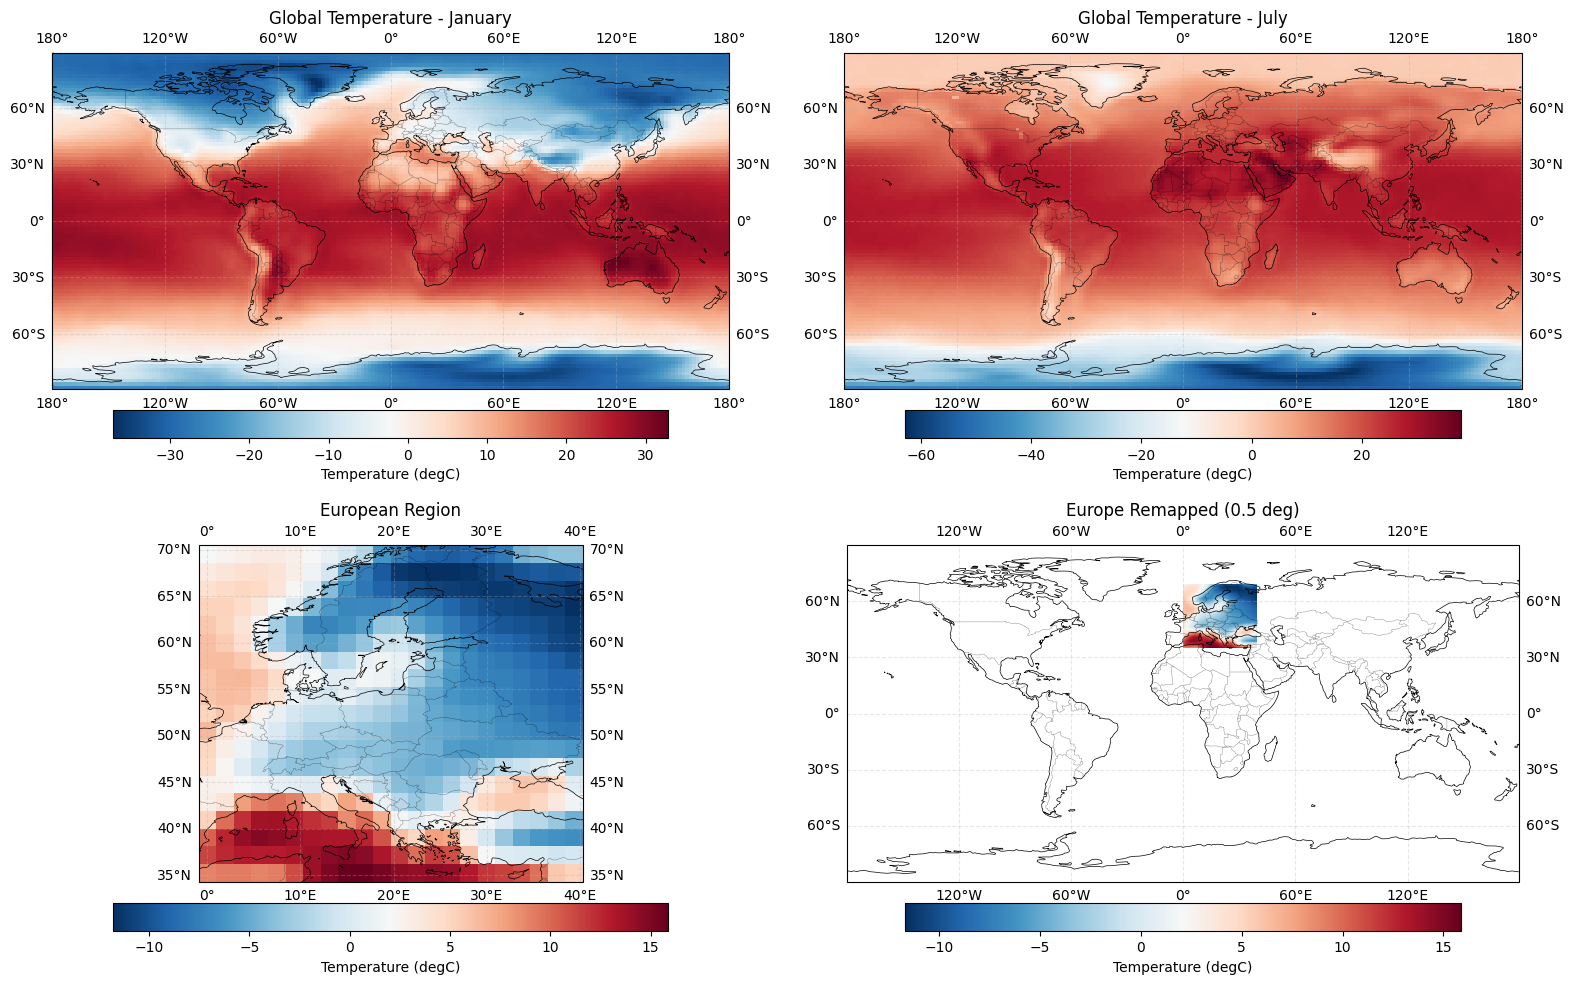

In [7]:
# Create map visualizations with cartopy
fig, axes = plt.subplots(2, 2, figsize=(16, 10),
                         subplot_kw={'projection': ccrs.PlateCarree()})

datasets = [
    (ds_global, 'Global Temperature - January', 0),
    (ds_global, 'Global Temperature - July', 1),
    (ds_region, 'European Region', 0),
    (ds_remap, 'Europe Remapped (0.5 deg)', 0),
]

for ax, (ds_data, title, t_idx) in zip(axes.flat, datasets):
    data_vals = ds_data.temperature[t_idx].values
    lon_vals = ds_data.lon.values
    lat_vals = ds_data.lat.values

    im = ax.pcolormesh(lon_vals, lat_vals, data_vals,
                       cmap='RdBu_r', transform=ccrs.PlateCarree(),
                       shading='auto')
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, alpha=0.5)
    ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, orientation='horizontal', pad=0.05,
                 label='Temperature (degC)', shrink=0.8)

plt.tight_layout()
plt.show()

## Exercises

1. Crop the dataset to the tropical region (23.5S to 23.5N) using `cdo sellonlatbox`
2. Remap the global data to a T63 (approx 1.9 deg) Gaussian grid
3. Compute the zonal mean using `cdo zonmean` and plot it
4. Use `cdo ggrid` to generate different grid descriptions
5. Compute the spatial standard deviation using `cdo fldstd`

Tropical region:
<xarray.Dataset> Size: 20kB
Dimensions:      (time: 2, lon: 97, lat: 24)
Coordinates:
  * time         (time) datetime64[ns] 16B 1980-01-01 1980-07-01
  * lon          (lon) float64 776B 0.0 1.875 3.75 5.625 ... 176.2 178.1 180.0
  * lat          (lat) float64 192B 21.9 20.0 18.09 16.19 ... -18.09 -20.0 -21.9
Data variables:
    temperature  (time, lat, lon) float32 19kB ...
Attributes:
    CDI:          Climate Data Interface version 2.6.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    source:       NCEP/DOE Reanalysis-2 (tas_sample.nc)
    title:        Real NCEP/DOE Reanalysis-2 temperature field
    history:      Sun Nov 22 18:49:42 2026: C:\Users\birhe\AppData\Roaming\Py...
    CDO:          Climate Data Operators version 2.6.0 (https://mpimet.mpg.de...


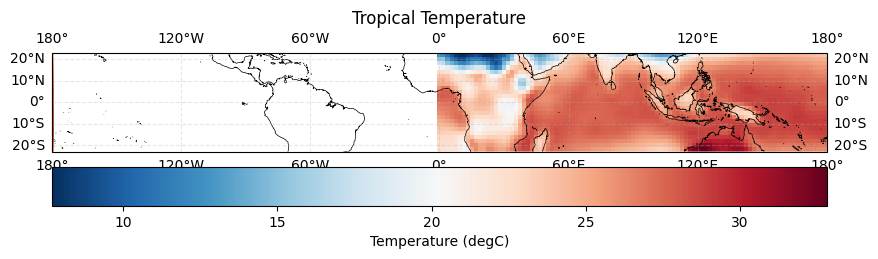

In [8]:
# Exercise 1: Crop to tropics
tropics_file = os.path.join(output_dir, 'tropics.nc')
subprocess.run([CDO, 'sellonlatbox,0,180,-23.5,23.5',
               spatial_file, tropics_file], capture_output=True, text=True)

ds_tropics = xr.open_dataset(tropics_file)
print('Tropical region:')
print(ds_tropics)

# Quick plot
fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
im = ax.pcolormesh(ds_tropics.lon, ds_tropics.lat, ds_tropics.temperature[0],
                    cmap='RdBu_r', transform=ccrs.PlateCarree(), shading='auto')
plt.colorbar(im, label='Temperature (degC)', orientation='horizontal', pad=0.05)
ax.coastlines(linewidth=0.5)
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.3)
plt.title('Tropical Temperature')
plt.show()

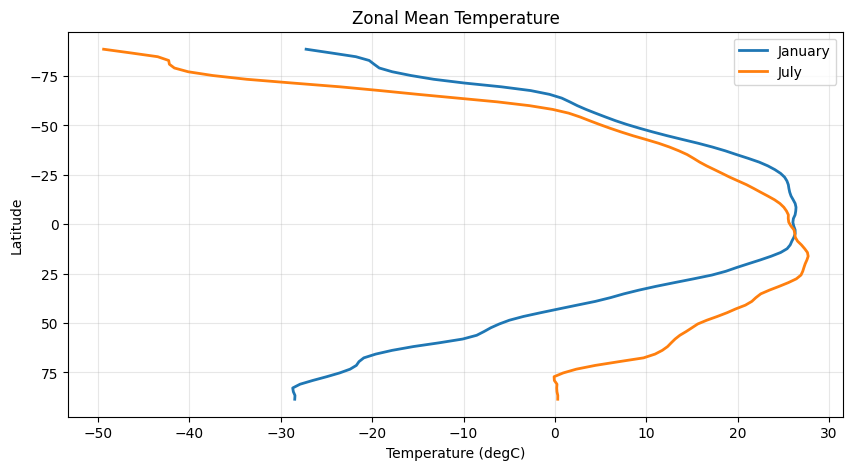

In [9]:
# Exercise 3: Zonal mean
subprocess.run([CDO, 'zonmean', spatial_file,
               os.path.join(output_dir, 'zonal_mean.nc')],
              capture_output=True, text=True)

ds_zonal = xr.open_dataset(os.path.join(output_dir, 'zonal_mean.nc'))

plt.figure(figsize=(10, 5))
plt.plot(ds_zonal.temperature[0], ds_zonal.lat, label='January', linewidth=2)
plt.plot(ds_zonal.temperature[1], ds_zonal.lat, label='July', linewidth=2)
plt.xlabel('Temperature (degC)')
plt.ylabel('Latitude')
plt.title('Zonal Mean Temperature')
plt.legend()
plt.grid(alpha=0.3)
plt.gca().invert_yaxis()  # South to North
plt.show()